<a href="https://colab.research.google.com/github/Danial-Arif/DigiLens/blob/main/Digitlens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [14]:
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
GPU available: False


In [15]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Training images: 60000
Testing images: 10000


Image shape: torch.Size([1, 28, 28])
Label: 5


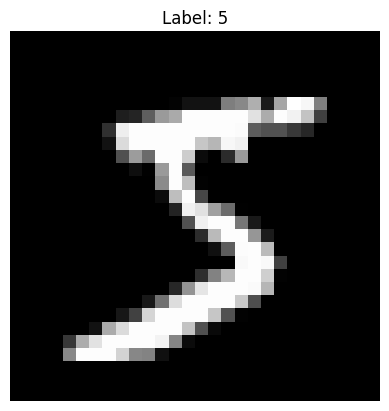

In [16]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

In [17]:
batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

In [18]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


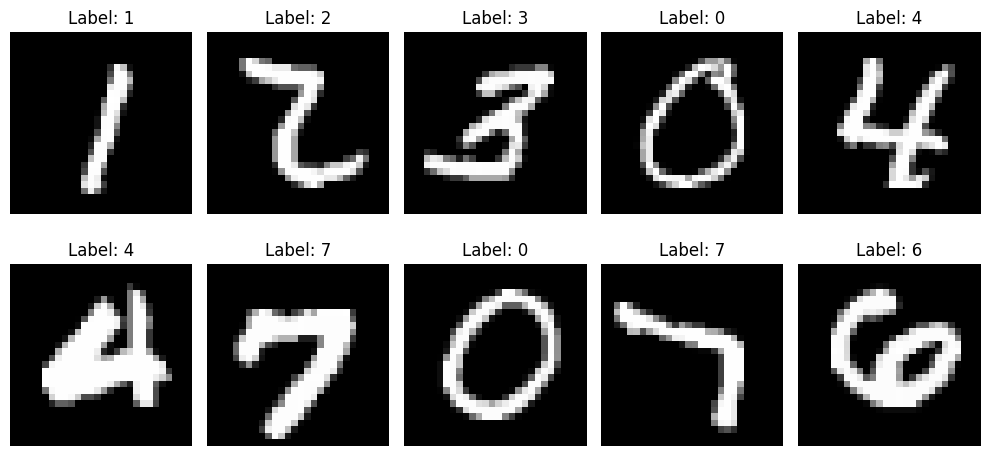

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
class DigitClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [21]:
model = DigitClassifier()

images, labels = next(iter(train_loader))

output = model(images)

print("Input shape:", images.shape)
print("Output shape:", output.shape)
print(output[0])

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
tensor([ 0.0582,  0.0143, -0.1342, -0.0714, -0.0713, -0.0303, -0.0401, -0.1248,
         0.0827,  0.1495], grad_fn=<SelectBackward0>)


In [22]:
loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [23]:
epochs = 5

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        # Forward pass
        output = model(images)

        # Calculate loss
        loss = loss_fn(output, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {average_loss:.4f}")

Epoch [1/5], Loss: 0.3552
Epoch [2/5], Loss: 0.1481
Epoch [3/5], Loss: 0.1013
Epoch [4/5], Loss: 0.0787
Epoch [5/5], Loss: 0.0604


In [24]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        output = model(images)

        predictions = torch.argmax(output, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Model Accuracy: {accuracy:.2f}%")

Model Accuracy: 97.66%


In [25]:
torch.save(model.state_dict(), "digit_model.pth")

print("Model saved successfully!")

Model saved successfully!


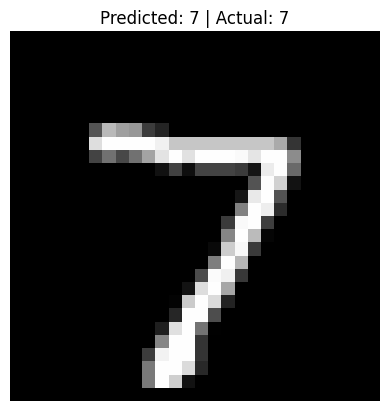

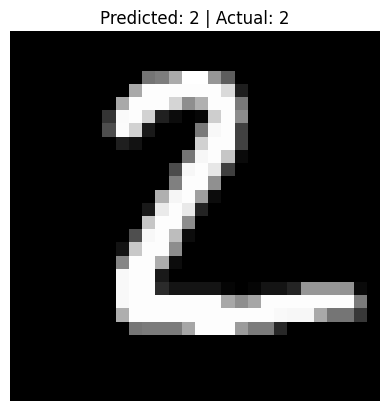

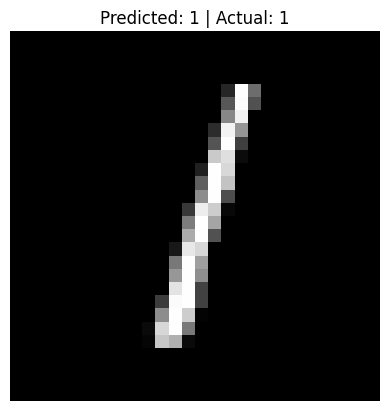

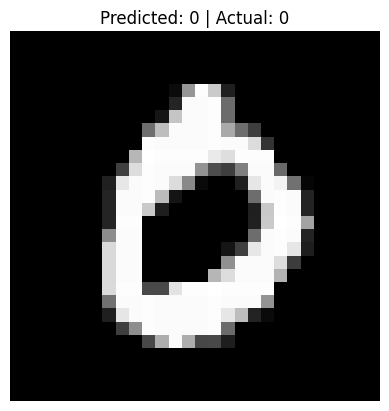

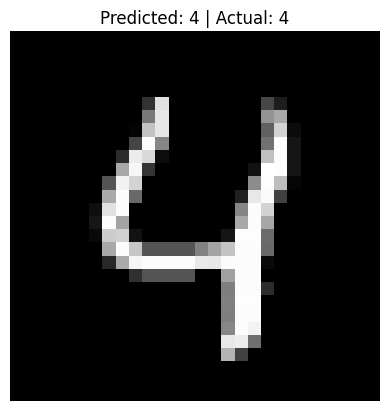

In [26]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    output = model(images)
    predictions = torch.argmax(output, dim=1)

for i in range(5):

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Predicted: {predictions[i].item()} | Actual: {labels[i].item()}"
    )

    plt.axis("off")
    plt.show()

In [27]:
model.eval()

all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        output = model(images)
        predictions = torch.argmax(output, dim=1)

        all_predictions.extend(predictions.tolist())

from collections import Counter

print(Counter(all_predictions))

Counter({1: 1141, 2: 1039, 3: 1038, 7: 1037, 9: 1005, 0: 981, 6: 969, 8: 965, 4: 958, 5: 867})
